# BED Paper Plots

Loads heavy-eval JSON files and plots `EIG (sPCE)` against the requested training samples used for milestone selection.

POLAR stands for policy learning with amortized belief representations.

Each location-finding block expects JSON files under `notebooks/final_results/location_finding/<setting>/`.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np

%load_ext autoreload
%autoreload 2

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() or (candidate / ".git").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from polar.utils.plotting import PAPER_COLORS, apply_style  # noqa: E402

# Switch to use_tex=True when rendering final paper-quality figures on a machine with LaTeX.
apply_style(use_tex=True, base_font_size=20)


def latest_match(pattern: str) -> Path | None:
    matches = sorted(REPO_ROOT.glob(pattern), key=lambda p: p.stat().st_mtime)
    return matches[-1] if matches else None

In [2]:
def load_curve(path: Path, label: str) -> pd.DataFrame:
    records = json.loads(path.read_text(encoding="utf-8"))
    rows = []
    for record in records:
        spce_mean = record.get("eval_spce_mean", record.get("spce_mean"))
        spce_stderr = record.get(
            "eval_spce_stderr",
            record.get("spce_stderr", record.get("spce_se")),
        )
        snmc_mean = record.get(
            "eval_snmc_mean",
            record.get("eval_nmc_mean", record.get("snmc_mean", record.get("nmc_mean"))),
        )
        snmc_stderr = record.get(
            "eval_snmc_stderr",
            record.get(
                "eval_nmc_stderr",
                record.get(
                    "snmc_stderr",
                    record.get("nmc_stderr", record.get("snmc_se", record.get("nmc_se"))),
                ),
            ),
        )
        # Prefer the requested budget used for milestone selection; fall back to
        # actual/legacy fields so older exports still load in this notebook.
        requested_likelihood_evals = record.get(
            "requested_likelihood_evals",
            record.get("total_likelihood_evals", record.get("requested_rollouts", record.get("total_rollouts"))),
        )
        total_likelihood_evals = record.get("total_likelihood_evals")
        total_rollouts = record.get("total_rollouts")
        if requested_likelihood_evals is None:
            continue
        rows.append(
            {
                "method": label,
                "requested_likelihood_evals": int(requested_likelihood_evals),
                "total_likelihood_evals": (
                    int(total_likelihood_evals) if total_likelihood_evals is not None else None
                ),
                "total_rollouts": int(total_rollouts) if total_rollouts is not None else None,
                "spce_mean": float(spce_mean) if spce_mean is not None else None,
                "spce_stderr": float(spce_stderr) if spce_stderr is not None else None,
                "snmc_mean": float(snmc_mean) if snmc_mean is not None else None,
                "snmc_stderr": float(snmc_stderr) if snmc_stderr is not None else None,
                "eig_mean": float(spce_mean) if spce_mean is not None else None,
                "eig_stderr": float(spce_stderr) if spce_stderr is not None else None,
                "checkpoint_path": record.get("checkpoint_path"),
            }
        )
    if not rows:
        return pd.DataFrame(
            columns=[
                "method",
                "requested_likelihood_evals",
                "total_likelihood_evals",
                "total_rollouts",
                "spce_mean",
                "spce_stderr",
                "snmc_mean",
                "snmc_stderr",
                "eig_mean",
                "eig_stderr",
                "checkpoint_path",
            ]
        )
    return pd.DataFrame(rows).sort_values("requested_likelihood_evals").reset_index(drop=True)


METHOD_MARKERS = {
    "POLAR": "*",
    "POLAR (frozen)": "D",
    "RL-BOED": "o",
    "DAD": "p",
    "ALINE": "v",
    "Random": "^",
    "POLAR (TabICL)": "*",
    "POLAR (TabPFN)": "o",
    "Frozen backbone": "D",
    "Coupled gradients": "s",
    "From scratch": "X",
}
METHOD_MARKER_SIZES = {
    "POLAR": 16,
    "POLAR (frozen)": 10,
    "RL-BOED": 12,
    "DAD": 14,
    "Random": 9,
    "ALINE": 13,
    "POLAR (TabICL)": 16,
    "POLAR (TabPFN)": 10,
    "Frozen backbone": 10,
    "Coupled gradients": 10,
    "From scratch": 11,
}

CURVE_X_COLUMN = "requested_likelihood_evals"
CURVE_X_LABEL = "Training samples"


def format_sci_tick(value: float, style: str = "cdot") -> str:
    r"""Format a scientific tick value.

    style="cdot" -> $3{\cdot}10^4$   (paper-standard, compact)
    style="times" -> $3\times 10^4$
    style="e"     -> 3e4               (technical/CS figures, shorter)
    """
    exponent = int(np.floor(np.log10(float(value))))
    mantissa = float(value) / 10 ** exponent
    mantissa_str = f"{mantissa:g}"
    if np.isclose(mantissa, 1.0):
        if style == "e":
            return f"1e{exponent}"
        return f"$10^{{{exponent}}}$"
    if style == "e":
        return f"{mantissa_str}e{exponent}"
    sep = "\\cdot" if style == "cdot" else "\\times"
    return f"${mantissa_str}{{{sep}}}10^{{{exponent}}}$"


def resolve_method_colors(
    *,
    method_colors: dict[str, str] | None = None,
    paper_color_indices: dict[str, int] | None = None,
) -> dict[str, str]:
    resolved = dict(method_colors or {})
    for method, color_idx in (paper_color_indices or {}).items():
        if color_idx <= 0:
            raise ValueError(f"paper color indices are 1-based; got {color_idx} for {method}.")
        resolved[method] = PAPER_COLORS[(int(color_idx) - 1) % len(PAPER_COLORS)]
    return resolved



def load_curves(sources: dict[str, Path | None]) -> pd.DataFrame:
    frames = []
    for label, path in sources.items():
        if path is None:
            continue
        path = Path(path)
        if not path.exists():
            print(f"Skipping {label}: {path} not found")
            continue
        frame = load_curve(path, label)
        if not frame.empty:
            frames.append(frame)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()



def plot_location_curve_block(
    curves: pd.DataFrame,
    *,
    title: str,
    random_baseline_eig: float | None = None,
    save_path: Path | str | None = None,
    show_legend: bool = True,
    method_colors: dict[str, str] | None = None,
    paper_color_indices: dict[str, int] | None = None,
    y_column: str = "eig_mean",
    stderr_column: str = "eig_stderr",
    ylabel: str = "EIG$(\\uparrow)$",
    xticks: list[float] | None = None,
    xtick_style: str = "cdot",
):
    if curves.empty:
        raise ValueError(f"No heavy-eval curves were loaded for {title}.")

    resolved_method_colors = resolve_method_colors(
        method_colors=method_colors,
        paper_color_indices=paper_color_indices,
    )

    metric_curves = curves.dropna(subset=[y_column, stderr_column])
    if metric_curves.empty:
        raise ValueError(f"No metric values were available for {title} using {y_column}.")

    fig, ax = plt.subplots(figsize=(5, 5))
    legend_handles = []
    legend_labels = []

    for method, frame in metric_curves.groupby("method", sort=False):
        marker = METHOD_MARKERS.get(method, "o")
        markersize = METHOD_MARKER_SIZES.get(method, 8)
        color = resolved_method_colors.get(method)
        ax.errorbar(
            frame[CURVE_X_COLUMN],
            frame[y_column],
            yerr=frame[stderr_column],
            marker=marker,
            markersize=markersize,
            markeredgewidth=1.2 if marker == "*" else 1.0,
            linewidth=2,
            elinewidth=2.4,
            capsize=11,
            capthick=2.2,
            barsabove=True,
            zorder=3,
            color=color,
        )
        legend_handles.append(
            Line2D(
                [0],
                [0],
                color=color,
                marker=marker,
                linewidth=2,
                markersize=markersize,
                markeredgewidth=1.2 if marker == "*" else 1.0,
            )
        )
        legend_labels.append(method)

    if random_baseline_eig is not None:
        random_color = resolved_method_colors.get("Random", "#7F7F7F")
        ax.axhline(
            random_baseline_eig,
            color=random_color,
            linestyle="--",
            linewidth=2,
        )
        if "Random" not in legend_labels:
            legend_handles.append(
                Line2D([0], [0], color=random_color, linestyle="--", linewidth=2)
            )
            legend_labels.append("Random")

    if "Random" in legend_labels:
        random_idx = legend_labels.index("Random")
        legend_handles = [legend_handles[random_idx], *legend_handles[:random_idx], *legend_handles[random_idx + 1 :]]
        legend_labels = [legend_labels[random_idx], *legend_labels[:random_idx], *legend_labels[random_idx + 1 :]]

    ax.set_xscale("log")
    if xticks is not None:
        ax.set_xticks(list(xticks))
        ax.set_xticklabels([format_sci_tick(v, style=xtick_style) for v in xticks])
        ax.get_xaxis().set_minor_locator(plt.NullLocator())
    ax.set_xlabel(CURVE_X_LABEL, size=24)
    ax.set_ylabel(ylabel, size=24)
    ax.set_title(title, size=26)
    ax.grid(alpha=0.2)
    if show_legend:
        ax.legend(legend_handles, legend_labels, handlelength=1.2, fontsize=16, loc="lower right",)

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


def plot_location_ablation_bar_block(
    curves: pd.DataFrame,
    *,
    title: str,
    method_order: list[str],
    method_colors: dict[str, str],
    save_path: Path | str | None = None,
    show_legend: bool = True,
    bar_width_log: float = 0.13,
    xtick_style: str = "cdot",
):
    if curves.empty:
        raise ValueError(f"No heavy-eval curves were loaded for {title}.")

    resolved_method_colors = resolve_method_colors(method_colors=method_colors)
    available_methods = [method for method in method_order if method in set(curves["method"])]
    if not available_methods:
        raise ValueError(f"No requested ablation methods were available for {title}.")

    budgets = sorted(int(value) for value in curves[CURVE_X_COLUMN].unique())
    n_methods = len(available_methods)
    half_bar_width_log = bar_width_log * 0.42

    fig, ax = plt.subplots(figsize=(5, 5))

    for idx, method in enumerate(available_methods):
        frame = curves[curves["method"] == method].set_index(CURVE_X_COLUMN)
        offset = (idx - (n_methods - 1) / 2) * bar_width_log
        x_positions = []
        widths = []
        heights = []
        errors = []

        for budget in budgets:
            if budget not in frame.index:
                continue
            row = frame.loc[budget]
            if isinstance(row, pd.DataFrame):
                row = row.iloc[0]

            center_log = np.log10(float(budget)) + offset
            left = 10 ** (center_log - half_bar_width_log)
            right = 10 ** (center_log + half_bar_width_log)
            x_positions.append(10 ** center_log)
            widths.append(right - left)
            heights.append(float(row["eig_mean"]))
            errors.append(float(row["eig_stderr"]))

        if not x_positions:
            continue

        color = resolved_method_colors.get(method, "#F28E2B")
        ax.bar(
            x_positions,
            heights,
            width=widths,
            color=color,
            label=method,
            zorder=3,
        )
        ax.errorbar(
            x_positions,
            heights,
            yerr=errors,
            fmt="none",
            ecolor="#5C2F0A",
            elinewidth=1.5,
            capsize=5,
            capthick=1.5,
            zorder=4,
        )

    x_tick_labels = [format_sci_tick(float(budget), style=xtick_style) for budget in budgets]

    pad = bar_width_log * (n_methods / 2 + 1.0)
    ax.set_xscale("log")
    ax.set_xlim(10 ** (np.log10(budgets[0]) - pad), 10 ** (np.log10(budgets[-1]) + pad))
    ax.set_xticks(budgets)
    ax.set_xticklabels(x_tick_labels)
    ax.set_xlabel(CURVE_X_LABEL, size=24)
    ax.set_ylabel("EIG$(\\uparrow)$", size=24)
    ax.set_title(title, size=26)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    if show_legend:
        ax.legend(
            loc="lower right",
            ncol=1,
            fontsize=18,
            framealpha=0.95,
            facecolor="white",
            edgecolor="#D8C7B4",
            handlelength=1.1,
            labelspacing=0.2,
            handletextpad=0.4,
        )

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()



In [3]:
SOURCES_2D_2K = {
    "DAD": REPO_ROOT / "notebooks/final_results/location_finding/2D_2K/dad/results.json",
    "RL-BOED": REPO_ROOT / "notebooks/final_results/location_finding/2D_2K/rl_boed/results.json",
    "ALINE": REPO_ROOT / "notebooks/final_results/location_finding/2D_2K/aline/results.json",
    "POLAR": latest_match("notebooks/final_results/location_finding/2D_2K/polar/results.json"),
}

curves_2d_2k = load_curves(SOURCES_2D_2K)
curves_2d_2k

,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
0,DAD,300000,300000,10000,5.585129,0.062690,5.587750,0.062900,5.585129,0.062690,<cluster-project>/outputs/hydra/2026-04-28/05-...
1,DAD,3000000,3000000,100000,7.122135,0.072849,7.151246,0.075380,7.122135,0.072849,<cluster-project>/outputs/hydra/2026-04-28/05-...
2,DAD,30000000,30000000,1000000,9.609291,0.062357,9.691313,0.066348,9.609291,0.062357,<cluster-project>/outputs/hydra/2026-04-28/05-...
3,DAD,300000000,300000000,10000000,10.536068,0.060159,10.781733,0.073381,10.536068,0.060159,<cluster-project>/outputs/hydra/2026-04-28/05-...
4,RL-BOED,300000,300000,10000,3.156452,0.052861,3.156814,0.052906,3.156452,0.052861,<cluster-rl-boed>/outputs/location_finding/red...
5,RL-BOED,3000000,3000000,100000,8.777995,0.063292,8.824620,0.066273,8.777995,0.063292,<cluster-rl-boed>/outputs/location_finding/red...
6,RL-BOED,30000000,30000000,1000000,10.469769,0.059232,10.629698,0.065804,10.469769,0.059232,<cluster-rl-boed>/outputs/location_finding/red...
7,RL-BOED,300000000,300000000,10000000,11.762074,0.051990,12.283361,0.070417,11.762074,0.051990,<cluster-rl-boed>/outputs/location_finding/red...
8,ALINE,300000,300000,10000,3.387818,0.062282,3.388806,0.062391,3.387818,0.062282,/scratch/work/huangd5/DecisionPFN/baselines/al...
9,ALINE,3000000,3000000,100000,5.215043,0.073107,5.220796,0.073644,5.215043,0.073107,/scratch/work/huangd5/DecisionPFN/baselines/al...


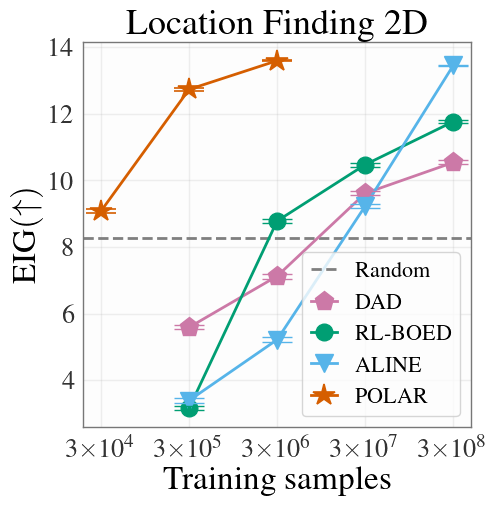

In [4]:
RANDOM_BASELINE_EIG_2D_2K = 8.28
LOCATION_2D_2K_PDF = REPO_ROOT / "figures" / "location_finding_2d_2k.pdf"

plot_location_curve_block(
    curves_2d_2k,
    title="Location Finding 2D",
    random_baseline_eig=RANDOM_BASELINE_EIG_2D_2K,
    paper_color_indices={"POLAR": 2, "RL-BOED": 3, "DAD": 4, "ALINE": 5},
    save_path=LOCATION_2D_2K_PDF,
    xticks=[3e4, 3e5, 3e6, 3e7, 3e8],
    xtick_style="times",  # "cdot" -> $3{\cdot}10^4$, "e" -> 3e4, "times" -> $3\times 10^4$
)



## Location Finding 5D (2K eval)

Same structure as the 2-D block above. Drop the exported JSON files into `notebooks/final_results/location_finding/5D_2K/` and rerun these two cells.


In [5]:
SOURCES_5D_2K = {
    "DAD": REPO_ROOT / "notebooks/final_results/location_finding/5D_2K/dad/results.json",
    "RL-BOED": REPO_ROOT / "notebooks/final_results/location_finding/5D_2K/rl_boed/results.json",
    "ALINE": REPO_ROOT / "notebooks/final_results/location_finding/5D_2K/aline/results.json",
    "POLAR": latest_match("notebooks/final_results/location_finding/5D_2K/polar/results.json"),
}

curves_5d_2k = load_curves(SOURCES_5D_2K)
curves_5d_2k

,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
0,DAD,500000,510000,10200,1.546121,0.042227,1.546138,0.042228,1.546121,0.042227,<cluster-project>/outputs/hydra/2026-04-28/14-...
1,DAD,5000000,5010000,100200,4.832751,0.070917,4.837246,0.071403,4.832751,0.070917,<cluster-project>/outputs/hydra/2026-04-28/14-...
2,DAD,50000000,50010000,1000200,9.091826,0.081821,9.209295,0.088035,9.091826,0.081821,<cluster-project>/outputs/hydra/2026-04-28/14-...
3,DAD,500000000,500010000,10000200,10.101696,0.079338,10.401838,0.094026,10.101696,0.079338,<cluster-project>/outputs/hydra/2026-04-28/14-...
4,RL-BOED,500000,500000,10000,2.002679,0.039198,2.002712,0.039202,2.002679,0.039198,<cluster-rl-boed>/outputs/location_finding/red...
5,RL-BOED,5000000,5000000,100000,7.165773,0.079959,7.186651,0.081219,7.165773,0.079959,<cluster-rl-boed>/outputs/location_finding/red...
6,RL-BOED,50000000,50000000,1000000,9.138092,0.078280,9.269395,0.085657,9.138092,0.078280,<cluster-rl-boed>/outputs/location_finding/red...
7,RL-BOED,500000000,500000000,10000000,9.095897,0.083861,9.212499,0.089634,9.095897,0.083861,<cluster-rl-boed>/outputs/location_finding/red...
8,ALINE,500000,500000,10000,4.678553,0.082137,4.687213,0.082963,4.678553,0.082137,/scratch/work/huangd5/DecisionPFN/baselines/al...
9,ALINE,5000000,5000000,100000,6.249951,0.086447,6.293787,0.090627,6.249951,0.086447,/scratch/work/huangd5/DecisionPFN/baselines/al...


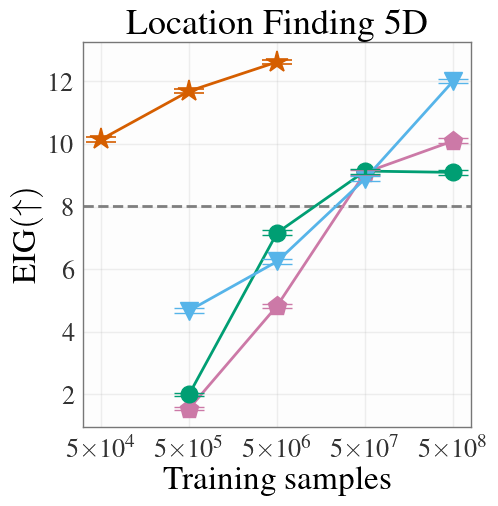

In [6]:
RANDOM_BASELINE_EIG_5D_2K = 8.02  # Set to a float once the 5-D random baseline is available.
LOCATION_5D_2K_PDF = REPO_ROOT / "figures" / "location_finding_5d_2k.pdf"

plot_location_curve_block(
    curves_5d_2k,
    title="Location Finding 5D",
    random_baseline_eig=RANDOM_BASELINE_EIG_5D_2K,
    paper_color_indices={"POLAR": 2, "RL-BOED": 3, "DAD": 4, "ALINE": 5},
    save_path=LOCATION_5D_2K_PDF,
    show_legend=False,
    xticks=[5e4, 5e5, 5e6, 5e7, 5e8],
    xtick_style="times",  # "cdot" -> $5{\cdot}10^4$, "e" -> 5e4, "times" -> $5\times 10^4$
)



## Location Finding sNMC (Appendix)

Plot appendix sNMC curves for the 2-D and 5-D location-finding benchmarks.


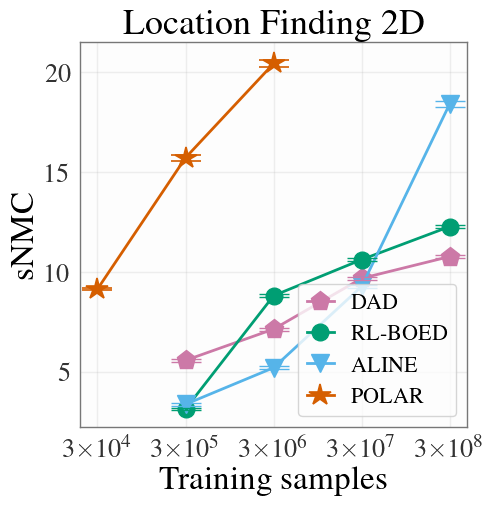

In [7]:
curves_2d_2k_snmc = load_curves(SOURCES_2D_2K)
LOCATION_2D_2K_SNMC_PDF = REPO_ROOT / "figures" / "location_finding_2d_2k_snmc.pdf"

plot_location_curve_block(
    curves_2d_2k_snmc,
    title="Location Finding 2D",
    paper_color_indices={"POLAR": 2, "RL-BOED": 3, "DAD": 4, "ALINE": 5},
    save_path=LOCATION_2D_2K_SNMC_PDF,
    y_column="snmc_mean",
    stderr_column="snmc_stderr",
    ylabel="sNMC",
    xticks=[3e4, 3e5, 3e6, 3e7, 3e8],
    xtick_style="times",
)


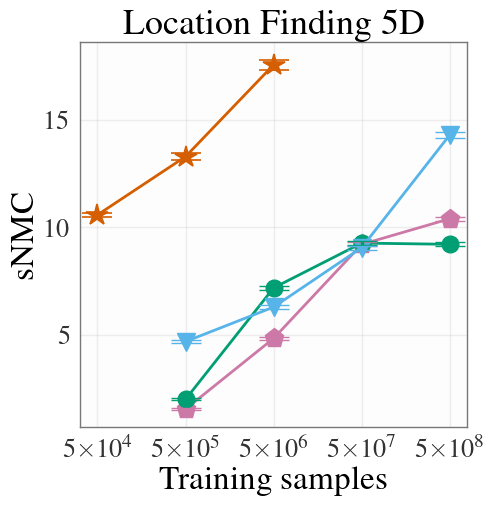

In [8]:
curves_5d_2k_snmc = load_curves(SOURCES_5D_2K)
LOCATION_5D_2K_SNMC_PDF = REPO_ROOT / "figures" / "location_finding_5d_2k_snmc.pdf"

plot_location_curve_block(
    curves_5d_2k_snmc,
    title="Location Finding 5D",
    paper_color_indices={"POLAR": 2, "RL-BOED": 3, "DAD": 4, "ALINE": 5},
    save_path=LOCATION_5D_2K_SNMC_PDF,
    show_legend=False,
    y_column="snmc_mean",
    stderr_column="snmc_stderr",
    ylabel="sNMC",
    xticks=[5e4, 5e5, 5e6, 5e7, 5e8],
    xtick_style="times",
)


## Location Finding Ablations

Plot location-finding ablations as grouped bars, with backbone choice shown separately for the appendix.


In [9]:
LOCATION_FINDING_ABLATION_METHOD_ORDER = [
    "POLAR",
    "Frozen backbone",
    "From scratch",
    "Coupled grads",
]

LOCATION_FINDING_ABLATION_SOURCES = {
    "POLAR": REPO_ROOT / "notebooks/final_results/location_finding/ablation/polar/results.json",
    "Frozen backbone": REPO_ROOT / "notebooks/final_results/location_finding/ablation/frozen_backbone/results.json",
    "From scratch": REPO_ROOT / "notebooks/final_results/location_finding/ablation/train_from_scratch/results.json",
    "Coupled grads": REPO_ROOT / "notebooks/final_results/location_finding/ablation/coupled_policy_gradients/results.json",
}

LOCATION_FINDING_ABLATION_COLORS = {
    "POLAR": "#FBE6BF",
    "Frozen backbone": "#E79A33",
    "From scratch": "#BF681D",
    "Coupled grads": "#5C2F0A",
}

LOCATION_FINDING_ABLATION_BUDGETS = [300000, 3000000]

LOCATION_FINDING_BACKBONE_SOURCES = {
    "POLAR (TabICL)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/polar/results.json",
    "POLAR (TabPFN)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/tabpfn/results.json",
}

LOCATION_FINDING_BACKBONE_METHOD_ORDER = [
    "POLAR (TabICL)",
    "POLAR (TabPFN)",
]

LOCATION_FINDING_BACKBONE_COLORS = {
    "POLAR (TabICL)": PAPER_COLORS[1],
    "POLAR (TabPFN)": "#355C9A",
}

curves_location_finding_ablation = load_curves(LOCATION_FINDING_ABLATION_SOURCES)
curves_location_finding_ablation = curves_location_finding_ablation[
    curves_location_finding_ablation[CURVE_X_COLUMN].isin(LOCATION_FINDING_ABLATION_BUDGETS)
].copy()

curves_location_finding_backbone_choice = load_curves(LOCATION_FINDING_BACKBONE_SOURCES)

curves_location_finding_ablation


,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
1,POLAR,300000,300000,6000,12.729088,0.051234,15.728127,0.146614,12.729088,0.051234,/scratch/project_2020109/POLAR/checkpoints/pol...
2,POLAR,3000000,3000000,60000,13.590996,0.021083,20.441933,0.175159,13.590996,0.021083,/scratch/project_2020109/POLAR/checkpoints/pol...
4,Frozen backbone,300000,300000,10000,10.833902,0.067980,11.305109,0.093418,10.833902,0.067980,/scratch/project_2020109/POLAR/checkpoints/pol...
5,Frozen backbone,3000000,3000000,100000,11.571396,0.062071,12.333359,0.096841,11.571396,0.062071,/scratch/project_2020109/POLAR/checkpoints/pol...
7,From scratch,300000,300000,6000,8.465059,0.058749,8.485644,0.059687,8.465059,0.058749,<cluster-project>/checkpoints/policy/location_...
8,From scratch,3000000,3000000,60000,8.382185,0.058627,8.399371,0.059361,8.382185,0.058627,<cluster-project>/checkpoints/policy/location_...
10,Coupled grads,300000,300000,6000,5.218805,0.059832,5.220149,0.059923,5.218805,0.059832,<cluster-project>/checkpoints/policy/location_...
11,Coupled grads,3000000,3000000,60000,9.170966,0.059719,9.373951,0.079490,9.170966,0.059719,<cluster-project>/checkpoints/policy/location_...


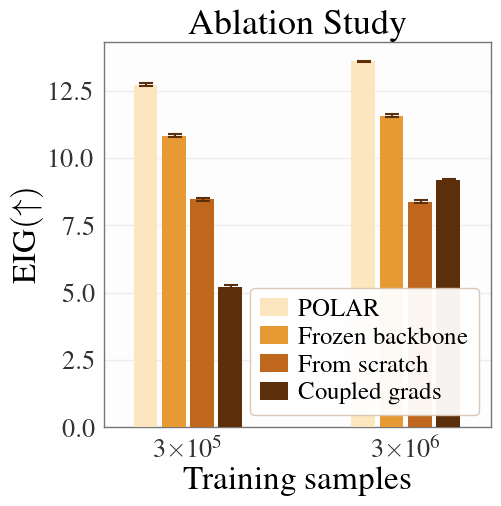

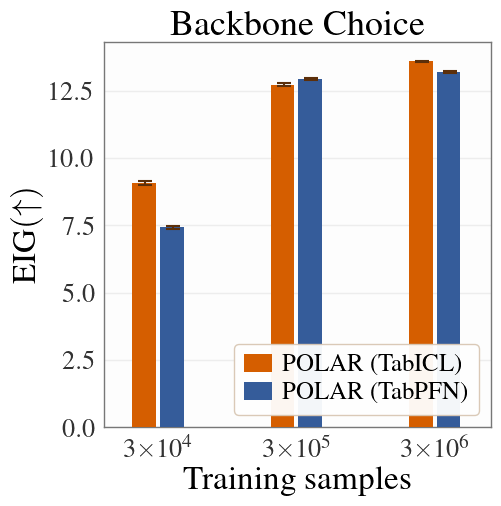

In [10]:
LOCATION_FINDING_ABLATION_PDF = REPO_ROOT / "figures" / "location_finding_ablation.pdf"

plot_location_ablation_bar_block(
    curves_location_finding_ablation,
    title="Ablation Study",
    method_order=LOCATION_FINDING_ABLATION_METHOD_ORDER,
    method_colors=LOCATION_FINDING_ABLATION_COLORS,
    save_path=LOCATION_FINDING_ABLATION_PDF,
    xtick_style="times",  # "cdot" -> $3{\cdot}10^4$ / $10^5$, "e" -> 3e4 / 1e5, "times" -> $3\times 10^4$
)

LOCATION_FINDING_BACKBONE_PDF = REPO_ROOT / "figures" / "location_finding_backbone_choice.pdf"

plot_location_ablation_bar_block(
    curves_location_finding_backbone_choice,
    title="Backbone Choice",
    method_order=LOCATION_FINDING_BACKBONE_METHOD_ORDER,
    method_colors=LOCATION_FINDING_BACKBONE_COLORS,
    save_path=LOCATION_FINDING_BACKBONE_PDF,
    bar_width_log=0.2,
    xtick_style="times",
)


### Different Policy Representation Layers

Compare TabICL policies that read the last, 2nd-to-last, 4th-to-last, and 8th-to-last ICL representations.


In [11]:
LOCATION_FINDING_LAYER_ABLATION_METHOD_ORDER = [
    "Last layer",
    "2nd-to-last",
    "4th-to-last",
    "8th-to-last",
]

LOCATION_FINDING_LAYER_ABLATION_SOURCES = {
    "Last layer": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers/-1/results.json",
    "2nd-to-last": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers/-2/results.json",
    "4th-to-last": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers/-4/results.json",
    "8th-to-last": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers/-8/results.json",
}

LOCATION_FINDING_LAYER_ABLATION_COLORS = {
    "Last layer": "#FBE6BF",
    "2nd-to-last": "#E79A33",
    "4th-to-last": "#BF681D",
    "8th-to-last": "#5C2F0A",
}

LOCATION_FINDING_LAYER_ABLATION_BUDGETS = [30000, 300000, 3000000]

curves_location_finding_layer_ablation = load_curves(LOCATION_FINDING_LAYER_ABLATION_SOURCES)
curves_location_finding_layer_ablation = curves_location_finding_layer_ablation[
    curves_location_finding_layer_ablation[CURVE_X_COLUMN].isin(LOCATION_FINDING_LAYER_ABLATION_BUDGETS)
].copy()

curves_location_finding_layer_ablation


,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
0,Last layer,30000,30000,600,9.075974,0.066104,9.156530,0.071340,9.075974,0.066104,/scratch/project_2020109/POLAR/checkpoints/pol...
1,Last layer,300000,300000,6000,12.729088,0.051234,15.728127,0.146614,12.729088,0.051234,/scratch/project_2020109/POLAR/checkpoints/pol...
2,Last layer,3000000,3000000,60000,13.590996,0.021083,20.441933,0.175159,13.590996,0.021083,/scratch/project_2020109/POLAR/checkpoints/pol...
3,2nd-to-last,30000,30000,600,10.058194,0.067845,10.321962,0.084931,10.058194,0.067845,<cluster-project>/checkpoints/policy/location_...
4,2nd-to-last,300000,300000,6000,12.766313,0.043417,14.965429,0.117820,12.766313,0.043417,<cluster-project>/checkpoints/policy/location_...
5,2nd-to-last,3000000,3000000,60000,13.396688,0.025682,16.940065,0.113669,13.396688,0.025682,<cluster-project>/checkpoints/policy/location_...
6,4th-to-last,30000,30000,600,8.852124,0.067808,8.937899,0.074059,8.852124,0.067808,<cluster-project>/checkpoints/policy/location_...
7,4th-to-last,300000,300000,6000,11.955420,0.056990,12.990428,0.097889,11.955420,0.056990,<cluster-project>/checkpoints/policy/location_...
8,4th-to-last,3000000,3000000,60000,13.293879,0.028904,16.630535,0.123178,13.293879,0.028904,<cluster-project>/checkpoints/policy/location_...
9,8th-to-last,30000,30000,600,8.060449,0.071677,8.124525,0.077308,8.060449,0.071677,<cluster-project>/checkpoints/policy/location_...


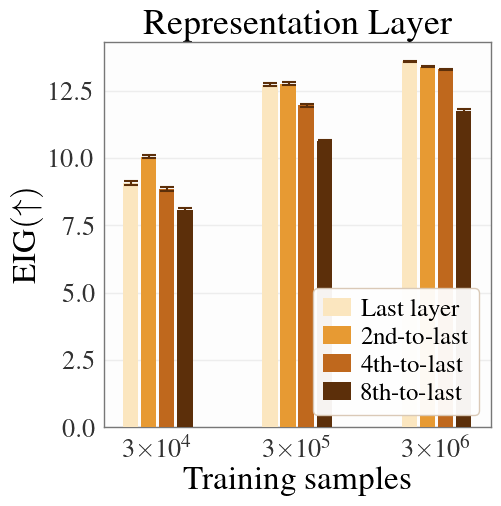

In [12]:
LOCATION_FINDING_LAYER_ABLATION_PDF = REPO_ROOT / "figures" / "location_finding_different_layers_ablation.pdf"

plot_location_ablation_bar_block(
    curves_location_finding_layer_ablation,
    title="Representation Layer",
    method_order=LOCATION_FINDING_LAYER_ABLATION_METHOD_ORDER,
    method_colors=LOCATION_FINDING_LAYER_ABLATION_COLORS,
    save_path=LOCATION_FINDING_LAYER_ABLATION_PDF,
    xtick_style="times",
)


In [13]:
LOCATION_FINDING_LAYER_ABLATION_METHOD_ORDER = [
    "Last layer (Frozen)",
    "2nd-to-last (Frozen)",
    "4th-to-last (Frozen)",
    "8th-to-last (Frozen)",
]

LOCATION_FINDING_LAYER_ABLATION_SOURCES = {
    "Last layer (Frozen)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers_frozen/-1/results.json",
    "2nd-to-last (Frozen)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers_frozen/-2/results.json",
    "4th-to-last (Frozen)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers_frozen/-4/results.json",
    "8th-to-last (Frozen)": REPO_ROOT / "notebooks/final_results/location_finding/ablation/different_layers_frozen/-8/results.json",
}

LOCATION_FINDING_LAYER_ABLATION_COLORS = {
    "Last layer (Frozen)": "#FBE6BF",
    "2nd-to-last (Frozen)": "#E79A33",
    "4th-to-last (Frozen)": "#BF681D",
    "8th-to-last (Frozen)": "#5C2F0A",
}

LOCATION_FINDING_LAYER_ABLATION_BUDGETS = [30000, 300000, 3000000]

curves_location_finding_layer_ablation = load_curves(LOCATION_FINDING_LAYER_ABLATION_SOURCES)
curves_location_finding_layer_ablation = curves_location_finding_layer_ablation[
    curves_location_finding_layer_ablation[CURVE_X_COLUMN].isin(LOCATION_FINDING_LAYER_ABLATION_BUDGETS)
].copy()

curves_location_finding_layer_ablation


,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
0,Last layer (Frozen),30000,30000,1000,9.554732,0.065409,9.693853,0.074599,9.554732,0.065409,/scratch/project_2020109/POLAR/checkpoints/pol...
1,Last layer (Frozen),300000,300000,10000,10.833902,0.067980,11.305109,0.093418,10.833902,0.067980,/scratch/project_2020109/POLAR/checkpoints/pol...
2,Last layer (Frozen),3000000,3000000,100000,11.571396,0.062071,12.333359,0.096841,11.571396,0.062071,/scratch/project_2020109/POLAR/checkpoints/pol...
3,2nd-to-last (Frozen),30000,30000,1000,9.881801,0.070469,10.146994,0.089129,9.881801,0.070469,<cluster-project>/checkpoints/policy/location_...
4,2nd-to-last (Frozen),300000,300000,10000,10.621249,0.069954,11.023416,0.091172,10.621249,0.069954,<cluster-project>/checkpoints/policy/location_...
5,2nd-to-last (Frozen),3000000,3000000,100000,11.408027,0.059145,11.981843,0.083994,11.408027,0.059145,<cluster-project>/checkpoints/policy/location_...
6,4th-to-last (Frozen),30000,30000,1000,9.231809,0.068053,9.361905,0.077720,9.231809,0.068053,<cluster-project>/checkpoints/policy/location_...
7,4th-to-last (Frozen),300000,300000,10000,9.866748,0.065396,10.035308,0.075461,9.866748,0.065396,<cluster-project>/checkpoints/policy/location_...
8,4th-to-last (Frozen),3000000,3000000,100000,10.710387,0.059562,11.009151,0.076093,10.710387,0.059562,<cluster-project>/checkpoints/policy/location_...
9,8th-to-last (Frozen),30000,30000,1000,7.960642,0.074823,8.033278,0.081252,7.960642,0.074823,<cluster-project>/checkpoints/policy/location_...


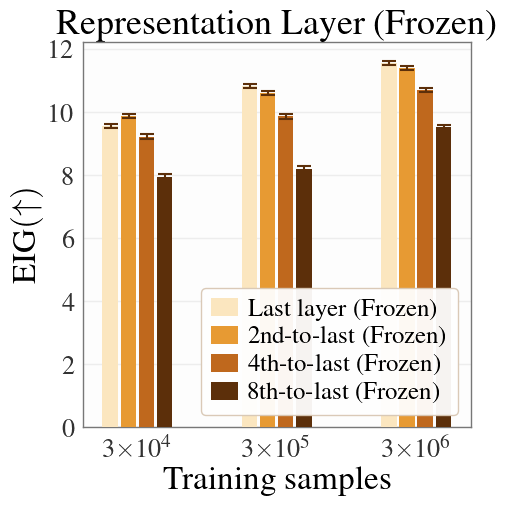

In [14]:
LOCATION_FINDING_LAYER_ABLATION_PDF = REPO_ROOT / "figures" / "location_finding_different_layers_frozen_ablation.pdf"

plot_location_ablation_bar_block(
    curves_location_finding_layer_ablation,
    title="Representation Layer (Frozen)",
    method_order=LOCATION_FINDING_LAYER_ABLATION_METHOD_ORDER,
    method_colors=LOCATION_FINDING_LAYER_ABLATION_COLORS,
    save_path=LOCATION_FINDING_LAYER_ABLATION_PDF,
    xtick_style="times",
)


In [15]:
CES = {
    "POLAR": latest_match("notebooks/final_results/ces/polar/results.json"),
    "RL-BOED": REPO_ROOT / "notebooks/final_results/ces/rl_boed/results.json",
    "DAD": REPO_ROOT / "notebooks/final_results/ces/dad/results.json",
    "ALINE": REPO_ROOT / "notebooks/final_results/ces/aline/results.json",
}

curves_ces = load_curves(CES)
curves_ces

,method,requested_likelihood_evals,total_likelihood_evals,total_rollouts,spce_mean,spce_stderr,snmc_mean,snmc_stderr,eig_mean,eig_stderr,checkpoint_path
0,POLAR,100000,100000,5000,11.150564,0.152304,12.087937,0.190810,11.150564,0.152304,/scratch/project_2020109/POLAR/checkpoints/pol...
1,POLAR,1000000,1000000,50000,13.104822,0.121045,16.244223,0.252579,13.104822,0.121045,/scratch/project_2020109/POLAR/checkpoints/pol...
2,POLAR,10000000,10000000,500000,14.112619,0.094130,20.090719,0.471654,14.112619,0.094130,/scratch/project_2020109/POLAR/checkpoints/pol...
3,RL-BOED,100000,100000,10000,11.036345,0.108894,11.206344,0.116728,11.036345,0.108894,<cluster-project>/outputs/ces/redq/2026-04-28/...
4,RL-BOED,1000000,1000000,100000,12.320057,0.127096,14.729134,1.245988,12.320057,0.127096,<cluster-project>/outputs/ces/redq/2026-04-28/...
5,RL-BOED,10000000,10000000,1000000,12.874388,0.117133,16.676134,0.384222,12.874388,0.117133,<cluster-project>/outputs/ces/redq/2026-04-28/...
6,RL-BOED,50000000,50000000,5000000,14.193933,0.088772,33.331982,1.801139,14.193933,0.088772,<cluster-project>/outputs/ces/redq/2026-04-28/...
7,DAD,100000,100000,10000,9.537936,0.137400,9.656527,0.143230,9.537936,0.137400,<cluster-project>/outputs/hydra/2026-04-28/02-...
8,DAD,1000000,1000000,100000,11.458987,0.159846,12.328768,0.194541,11.458987,0.159846,<cluster-project>/outputs/hydra/2026-04-28/02-...
9,DAD,10000000,10000000,1000000,12.874966,0.137700,16.442808,0.385068,12.874966,0.137700,<cluster-project>/outputs/hydra/2026-04-28/02-...


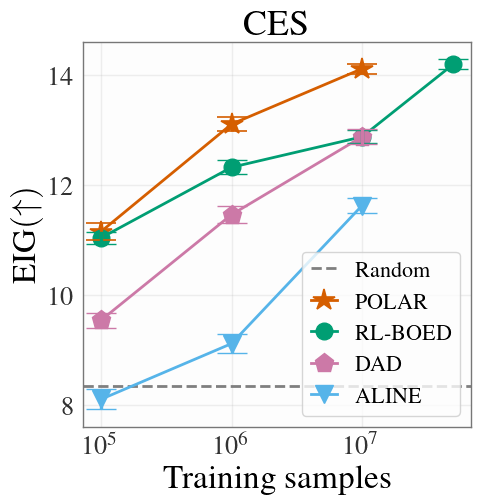

In [16]:
RANDOM_BASELINE_EIG_CES = 8.34  # Set to a float once the 5-D random baseline is available.
CES_PDF = REPO_ROOT / "figures" / "ces.pdf"

plot_location_curve_block(
    curves_ces,
    title="CES",
    random_baseline_eig=RANDOM_BASELINE_EIG_CES,
    paper_color_indices={"POLAR": 2, "RL-BOED": 3, "DAD": 4, "ALINE": 5},
    save_path=CES_PDF,
)



## Location Checkpoint Plot

Reuses the `evaluate_bed.py` loading logic so you can paste a single checkpoint path and render the 2-D location-finding trajectory/query plot used in BED evaluation.
s

In [17]:
import torch
import polar.utils.plotting as plotting_utils

from polar.evaluation import rollout_location_trajectory_from_checkpoint



def get_location_checkpoint_trajectory(
    checkpoint_path: Path | str,
    theta,
    *,
    device: str = "cpu",
    seed: int = 42,
    num_acquisitions: int | None = None,
    n_query_eval: int | None = 2000,
    greedy: bool = True,
):
    """Load a checkpoint and return a single [T, 2] location-finding trajectory."""
    result = rollout_location_trajectory_from_checkpoint(
        checkpoint_path,
        theta,
        device=device,
        seed=seed,
        num_acquisitions=num_acquisitions,
        n_query_eval=n_query_eval,
        greedy=greedy,
    )
    return result["x_traj"].cpu().numpy()



def plot_location_design_trajectory(
    theta,
    x_traj,
    *,
    design_min: float = 0.0,
    design_max: float = 1.0,
    title: str | None = None,
    save_path: Path | str | None = None,
    ax=None,
):
    """Plot one trajectory or a dict of method -> trajectory for 2-D location-finding."""
    if isinstance(x_traj, dict):
        fig, axes = plotting_utils.plot_location_trajectories_comparison_2d(
            theta,
            x_traj,
            design_min=design_min,
            design_max=design_max,
        )
        if save_path is not None:
            save_path = Path(save_path).expanduser().resolve()
            save_path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(save_path, dpi=180, bbox_inches="tight")
        return fig, axes

    fig, ax = plotting_utils.plot_location_trajectory_2d(
        theta,
        x_traj,
        design_min=design_min,
        design_max=design_max,
        title=title,
        ax=ax,
    )
    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=180, bbox_inches="tight")
    return fig, ax



/Users/daolanghuang/Desktop/POLAR/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


In [18]:
CHECKPOINT_PATH = latest_match(
    "notebooks/final_results/location_finding/2D_2K/polar/checkpoint_likelihood_evals_3000000.pt"
)
if CHECKPOINT_PATH is None:
    raise FileNotFoundError("No checkpoint_likelihood_evals_*.pt file found for this setting.")
THETA_TRUE = torch.tensor(
    [
        [0.2, 0.7],
        [0.8, 0.3],
    ],
    dtype=torch.float32,
)
PLOT_DEVICE = "cpu"
PLOT_SEED = 43
PLOT_NUM_ACQUISITIONS = None  # None -> use the checkpoint's training setting
PLOT_N_QUERY_EVAL = 2000
PLOT_GREEDY = True
PLOT_SAVE_PATH = REPO_ROOT / "figures" / "location_finding_fixed_theta_trajectory.pdf"

CHECKPOINT_PATH



PosixPath('/Users/daolanghuang/Desktop/POLAR/notebooks/final_results/location_finding/2D_2K/polar/checkpoint_likelihood_evals_3000000.pt')

In [19]:
x_traj = get_location_checkpoint_trajectory(
    CHECKPOINT_PATH,
    THETA_TRUE,
    device=PLOT_DEVICE,
    seed=PLOT_SEED,
    num_acquisitions=PLOT_NUM_ACQUISITIONS,
    n_query_eval=PLOT_N_QUERY_EVAL,
    greedy=PLOT_GREEDY,
)

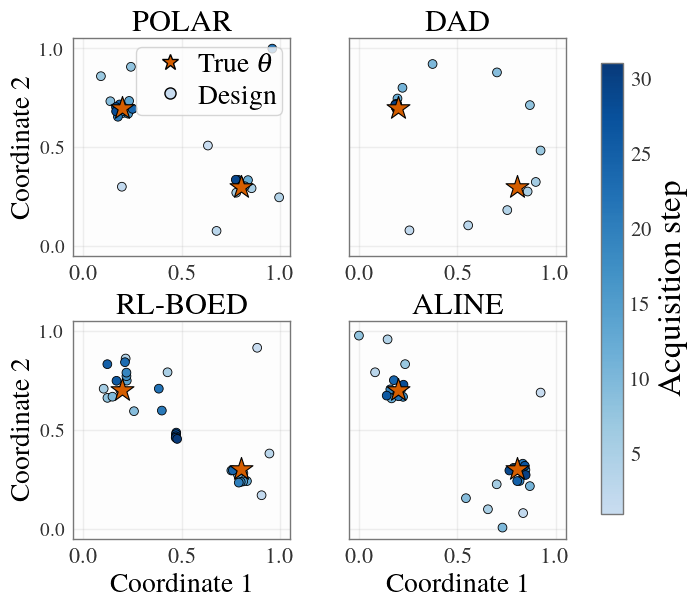

In [20]:
traj_dict = {
    "POLAR": x_traj,
    "DAD": np.load(REPO_ROOT / "notebooks/final_results/location_finding/trajectory_viz/location_finding_trajectory_dad.npy"),
    "RL-BOED": np.load(REPO_ROOT / "notebooks/final_results/location_finding/trajectory_viz/location_finding_trajectory_rl_boed.npy"),
    "ALINE": np.load(REPO_ROOT / "notebooks/final_results/location_finding/trajectory_viz/location_finding_trajectory_aline.npy"),
}

fig, axes = plot_location_design_trajectory(
    THETA_TRUE,
    traj_dict,
    save_path=PLOT_SAVE_PATH,
)
